# Testing DLP: Training a Basic RNN 

In this notebook, we construct and run a basic LSTM-RNN (based on code written by Nicole Hartman, Winter - Summer 2018) to ensure that functionality is established in the DLP framework. Creation Date: July 30, 2018

In [2]:
import sys
PYTHONPATH="../"
sys.path.append(PYTHONPATH)
import models 
from train import * 
import matplotlib.pyplot as py 
%matplotlib inline 
import numpy as np 

In [2]:
# first, we'll generate input data using the toy RNN dataset in the preprocess_outputs folder 
data_file = "../Preprocess/preprocess_outputs/RNN_DLP_Test1_15trks_1k_noNorm.hdf5"

X_train, y_train_cat, ix_train, weights_train = models.rnn_input_simple(data_file, nJets = 1e3)

In [3]:
# let's explore the output 
type(X_train) # --> numpy array 
print(X_train.shape)
print(y_train_cat.shape)
print(ix_train.shape)
print(weights_train.shape)

(323, 15, 5)
(323, 4)
(323,)
(323,)


In [4]:
# construct an LSTM-RNN 
num_hidden = 5
num_dense = 5
jets = 1e3 
rnn_model = models.LSTM_class(num_hidden, num_dense, nJets = jets)

In [5]:
# try to train the model! 
rnn_history = rnn_train(rnn_model, X_train, y_train_cat, weights_train, filepath="../Results/rnn_first_test.h5")

Train on 258 samples, validate on 65 samples
Epoch 1/50
258/258 [==============================] - 1s - loss: 1.4538 - acc: 0.2054 - val_loss: 1.4081 - val_acc: 0.2615
Epoch 2/50
258/258 [==============================] - 0s - loss: 1.4479 - acc: 0.2674 - val_loss: 1.4008 - val_acc: 0.2923
Epoch 3/50
258/258 [==============================] - 0s - loss: 1.4372 - acc: 0.2674 - val_loss: 1.3942 - val_acc: 0.3231
Epoch 4/50
258/258 [==============================] - 0s - loss: 1.4268 - acc: 0.3488 - val_loss: 1.3883 - val_acc: 0.3231
Epoch 5/50
258/258 [==============================] - 0s - loss: 1.4216 - acc: 0.3837 - val_loss: 1.3832 - val_acc: 0.3846
Epoch 6/50
258/258 [==============================] - 0s - loss: 1.4188 - acc: 0.3798 - val_loss: 1.3784 - val_acc: 0.3692
Epoch 7/50
258/258 [==============================] - 0s - loss: 1.4109 - acc: 0.4419 - val_loss: 1.3736 - val_acc: 0.3846
Epoch 8/50
258/258 [==============================] - 0s - loss: 1.4023 - acc: 0.4109 - val_lo

Not quite sure what's happening here --> take a look at why the val accuracy is constant! 
The learning rate was way too low; default is ~1e-3, I had 1e-5! 

In [6]:
# now trying with the default value (above was run with default==False)
rnn_Default = models.LSTM_class(num_hidden, num_dense, nJets = jets)
# run with default = True --> Adam = optimizer.Adam() 
rnn_Def_history = rnn_train(rnn_Default, X_train, y_train_cat, weights_train, save=False, default=True)

Train on 258 samples, validate on 65 samples
Epoch 1/50
258/258 [==============================] - 1s - loss: 1.4356 - acc: 0.3372 - val_loss: 1.3721 - val_acc: 0.4000
Epoch 2/50
258/258 [==============================] - 0s - loss: 1.4274 - acc: 0.4457 - val_loss: 1.3643 - val_acc: 0.4308
Epoch 3/50
258/258 [==============================] - 0s - loss: 1.4226 - acc: 0.4535 - val_loss: 1.3559 - val_acc: 0.4462
Epoch 4/50
258/258 [==============================] - 0s - loss: 1.4082 - acc: 0.4884 - val_loss: 1.3468 - val_acc: 0.5077
Epoch 5/50
258/258 [==============================] - 0s - loss: 1.4031 - acc: 0.4729 - val_loss: 1.3369 - val_acc: 0.4923
Epoch 6/50
258/258 [==============================] - 0s - loss: 1.3839 - acc: 0.5116 - val_loss: 1.3257 - val_acc: 0.4923
Epoch 7/50
258/258 [==============================] - 0s - loss: 1.3779 - acc: 0.5349 - val_loss: 1.3140 - val_acc: 0.5077
Epoch 8/50
258/258 [==============================] - 0s - loss: 1.3630 - acc: 0.5233 - val_lo

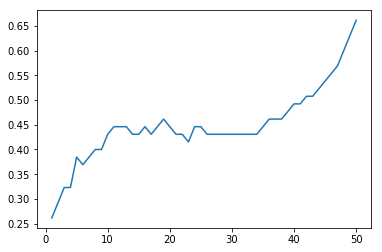

In [7]:
# plot the first rnn 
val_acc_nonDefault = rnn_history.history['val_acc']
epochs = np.arange(1, 51)
py.plot(epochs, val_acc_nonDefault)

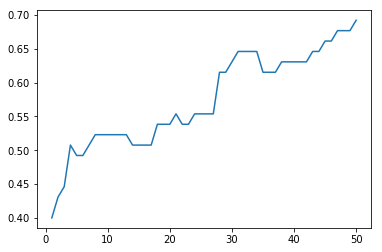

In [8]:
# plot the second rnn 
val_acc_default = rnn_Def_history.history['val_acc']
py.plot(epochs, val_acc_default)

In [12]:
# some testing to figure out how to select validation set from rnn training data 
array = np.array([1, 2, 3, 4, 5, 6])
Y_array = np.array(['a', 'b', 'c', 'd', 'e', 'f'])
array_indices = np.arange(6)
random_indices = np.random.choice(array_indices, size=3, replace=False)
random_Y = Y_array[random_indices]
random_X = array[random_indices]

print(random_indices)
print(random_X)
print(random_Y)

[5 0 1]
[6 1 2]
['f' 'a' 'b']


In [16]:
# deleting the selected validation data from the training data
print(random_indices)
print(array)
new_array = np.delete(array, random_indices)
new_Y_array = np.delete(Y_array, random_indices)
print(new_array)
print(new_Y_array)

[5 0 1]
[1 2 3 4 5 6]
[3 4 5]
['c' 'd' 'e']
